# Ratings, the master scale and the through-the-cycle PD of a grade

**Question:** What PD should each grade of a seven-grade rating scale carry on its master scale, and how far does the default rate of a single year stray from that through-the-cycle level?

- **Level:** 1, Fundamentals
- **Prerequisites:** notebooks 01 to 04 of topic 01 (the engine, an artifact, a first test)
- **Reading time:** about 30 minutes

## Objectives

By the end of this notebook you can:

- read a rating agency's cohort table: the grades, the default state, the withdrawn ratings and the cohort size;
- turn one year's counts into a one-year PD by grade with the engine's cohort estimator, and say what the withdrawn ratings do to it;
- say why one year's PD is a point-in-time number and the average of many years is the through-the-cycle number a master scale needs;
- link the two with the one-factor (Merton-Vasicek) model and read the credit-cycle factor each year implies;
- find the portfolio a pooled matrix converges to and the default rate it carries.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.engines import vasicek
from riskvalidation.regulatory import irb
from riskvalidation.transitions import estimators, intervals, ttc

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is case C04 of Contraste, the S&P variant, as the product commits it. The source is ESMA's CEREP publication, the register where credit rating agencies report their ratings and their transitions (licence class `mirror-allowed`, attribution carried in the artifact: "Source: ESMA CEREP; tables transformed by Contraste"; https://registers.esma.europa.eu/cerep-publication/). The pipeline took the corporate, long-term ratings of the EU entity of S&P by category, put them on **seven performing grades** (AAA, AA, A, BBB, BB, B, CCC-C) plus **default**, and kept one table per annual **cohort**: the ratings alive on 1 January and where each stood on 31 December.

- **File read:** `data/derived/C04/sp.json`, keys `outputs.cohorts` (26 annual cohorts), `outputs.pd` (the one-year PD by cohort and grade under four definitions), `outputs.lra` (the long-run averages), `outputs.pooled` and `outputs.origination` (the pooled matrix and the cohort mix).
- **The definition matters.** CEREP states that "no deterministic definition of a default event has been set up", so each PD names its page. This notebook uses `d4`, the PD read off the transition page (the default column over the cohort less its withdrawals), the industry treatment. Notebook 10 of this topic shows how much the choice of page moves a PD.

The next cell loads the artifact and prints what it holds.

In [2]:
# Load the artifact (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
sp = json.loads((ROOT / "data" / "derived" / "C04" / "sp.json").read_text(encoding="utf-8"))
out = sp["outputs"]
grades, states = out["grades"], out["states"]
cohorts = out["cohorts"]
years = [c["label"] for c in cohorts]

print("agency:", out["agency"]["name"])
print("grades:", grades)
print("annual cohorts:", len(cohorts), "from", years[0], "to", years[-1])
print("engine that baked the artifact:", sp["provenance"]["riskvalidation_version"])

agency: Standard & Poor's Credit Market Services Europe Limited
grades: ['AAA', 'AA', 'A', 'BBB', 'BB', 'B', 'CCC-C']
annual cohorts: 26 from 2000 to 2025
engine that baked the artifact: 1.0.1


## Method

### Step 1: the one-year PD of a grade from one cohort

Each cohort record holds, for the ratings alive at the start of the year, the `counts` of where they stood at the end (rows the grade at the start, columns the seven grades and default) and the `withdrawn` ratings: the ones the agency stopped rating during the year, whose end state is unknown. The 2000 cohort is the first of the 26.

The cohort estimator of Anderson and Goodman (1957, equations 2.8 and 2.9) estimates the probability of moving from grade $i$ to state $j$ in one year as the share of the ratings that started in $i$ and ended in $j$:

$$\hat p_{ij} = \frac{N_{ij}}{N_i}$$

with $N_i$ the ratings that started in $i$ and are still observed at the end. The PD of grade $i$ is the entry of the default column, $\hat p_{i,D}$. The withdrawn ratings are not in $N_i$: the industry standard, "the method which has emerged as an industry standard" (Schuermann and Hanson, 2004, footnote 4), treats a withdrawal as non-informative and spreads it over the states in proportion to their values, which is the same as removing it and dividing by what remains.

The engine's `cohort` takes a square table, so the next cell adds an empty default row (default is absorbing) and calls it with `treatment="exclude"`. It prints, per grade, the ratings still observed at the end, the share withdrawn and the one-year PD, which is the default column of the matrix.

In [3]:
# The 2000 table made square with an empty default row, then one call of the cohort estimator
c2000 = cohorts[0]
counts = np.array(c2000["counts"], dtype=float)
withdrawn = np.append(np.array(c2000["withdrawn"], dtype=float), 0.0)
square = np.vstack([counts, np.zeros(len(states))])
m_exclude = estimators.cohort(square, withdrawn, treatment="exclude")
p2000 = m_exclude["matrix"]

print(f"{'grade':8s}{'observed':>14s}{'withdrawn':>14s}{'PD':>10s}")
for g in range(7):
    observed = int(m_exclude["row_sizes"][g])
    share = 100 * m_exclude["withdrawn_share"][g]
    print(f"{grades[g]:8s}{observed:14d}{share:13.1f}%{100 * p2000[g, -1]:9.2f}%")

grade         observed     withdrawn        PD
AAA                229          5.0%     0.00%
AA                 852          7.7%     0.00%
A                 1637          6.0%     0.24%
BBB               1656          5.4%     0.36%
BB                1016          7.1%     0.30%
B                  951         11.1%     5.57%
CCC-C              109         23.2%    17.43%


The figure draws the whole matrix, each row the grade at the start of 2000 and each column the state at its end, in percent. The weight sits on the diagonal and one notch off it, and the default column is close to zero everywhere except in the weakest grades.

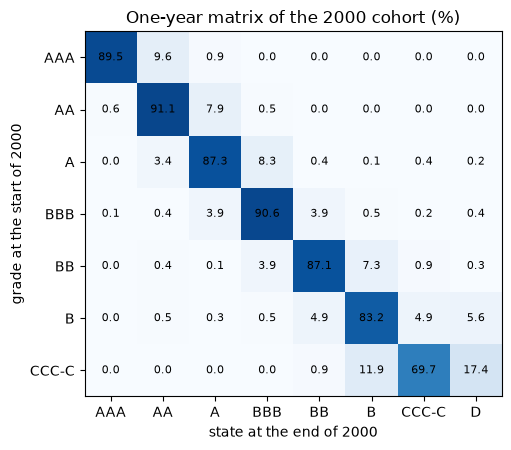

In [4]:
# Draw the one-year matrix of the 2000 cohort, in percent, with each cell written on it
fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.imshow(p2000[:7], cmap="Blues", vmin=0, vmax=1)
for i in range(7):
    for j in range(8):
        ax.text(j, i, f"{100 * p2000[i, j]:.1f}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(8))
ax.set_xticklabels(states)
ax.set_yticks(range(7))
ax.set_yticklabels(grades)
ax.set_xlabel("state at the end of 2000")
ax.set_ylabel("grade at the start of 2000")
ax.set_title("One-year matrix of the 2000 cohort (%)")
fig.tight_layout()
plt.show()

Read the matrix row by row. A BBB rating of 2000 stayed BBB nine times in ten and moved one notch up or down most of the rest of the time; AAA never defaulted and AA neither. The first defaults appear in A, with a PD below 0.3%, and grow to 5.57% in B and 17.43% in CCC-C. The picture does not show how far these numbers can be trusted: a cell with a handful of ratings behind it moves a lot with one event, and it does not show what the withdrawn ratings hide, which is the next step.

### Step 2: what the withdrawn ratings do to a PD

If a withdrawal is not informative, removing it is harmless. If a rating is withdrawn because the borrower is in trouble, removing it understates the PD. The engine's other treatment, `treatment="state"`, keeps the withdrawn ratings in the denominator as a ninth, absorbing state, which is how EBA/GL/2017/16 paragraph 76 keeps closed obligations in the sample. The next cell runs the cohort estimator a second time with that treatment and sets the two PDs side by side.

In [5]:
# The same cohort with the withdrawn ratings kept as an absorbing state, beside the removal
m_state = estimators.cohort(square, withdrawn, treatment="state")
pd_removed = p2000[:7, -1]
pd_kept = m_state["matrix"][:7, len(states) - 1]   # column 7 is default, column 8 the withdrawn state

print(f"{'grade':8s}{'removed':>12s}{'kept':>12s}{'ratio':>8s}")
for g in range(2, 7):
    ratio = pd_removed[g] / pd_kept[g]
    print(f"{grades[g]:8s}{100 * pd_removed[g]:11.2f}%{100 * pd_kept[g]:11.2f}%{ratio:8.2f}")

grade        removed        kept   ratio
A              0.24%       0.23%    1.06
BBB            0.36%       0.34%    1.06
BB             0.30%       0.27%    1.08
B              5.57%       4.95%    1.13
CCC-C         17.43%      13.38%    1.30


The next cell draws the two PDs of the speculative grades side by side, on a logarithmic axis so that A and CCC-C can share it.

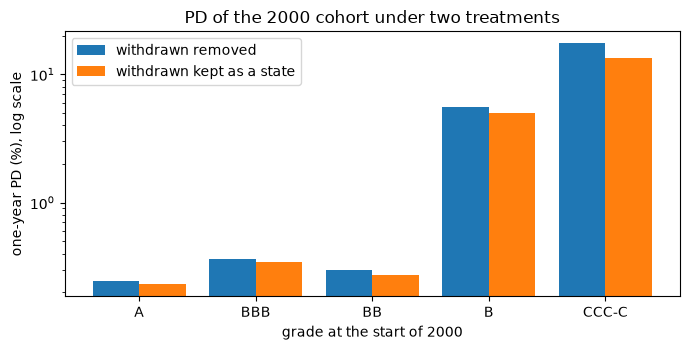

In [6]:
# Draw the PD of the speculative-grade ratings with the withdrawn ratings removed and kept
fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(5)
ax.bar(x - 0.2, 100 * pd_removed[2:], 0.4, color="tab:blue", label="withdrawn removed")
ax.bar(x + 0.2, 100 * pd_kept[2:], 0.4, color="tab:orange", label="withdrawn kept as a state")
ax.set_xticks(x)
ax.set_xticklabels(grades[2:])
ax.set_yscale("log")
ax.set_xlabel("grade at the start of 2000")
ax.set_ylabel("one-year PD (%), log scale")
ax.set_title("PD of the 2000 cohort under two treatments")
ax.legend()
fig.tight_layout()
plt.show()

Keeping the withdrawn ratings lowers every PD, and the gap widens as the grade worsens: it is about 6% in A and BBB, 13% in B and 30% in CCC-C, the grades where the agency withdrew the largest share of its ratings (11% of B and 23% of CCC-C in 2000). The figure shows that the choice matters most exactly where the PD matters most. It cannot say which treatment is right: that depends on whether a withdrawal says anything about the borrower, an assumption notebook 10 of this topic tests on rating paths whose truth is known.

### Step 3: from one year to the through-the-cycle PD

One year's PD is a point-in-time number: it moves with the economy. The master scale of a rating system needs the through-the-cycle (TTC) PD of each grade, the level the grade has over a whole cycle. The EBA guidelines (EBA/GL/2017/16, paragraph 84) define it as the long-run average of the one-year default rates, "the observed average of the one-year default rates", over the cohorts where the grade has ratings:

$$\mathrm{LRA}_i = \frac{1}{T_i} \sum_{t=1}^{T_i} \hat p_{i,D}(t)$$

The next cell runs the cohort estimator on each of the 26 annual tables and keeps the default column of every one, which gives the yearly PD of each grade.

In [7]:
# One call of the cohort estimator per annual table, the default column of each kept as that year's PD
tables = []
gone = []
yearly = []
for c in cohorts:
    tables.append(np.vstack([np.array(c["counts"], dtype=float), np.zeros(len(states))]))
    gone.append(np.append(np.array(c["withdrawn"], dtype=float), 0.0))
    matrix = estimators.cohort(tables[-1], gone[-1], treatment="exclude")["matrix"]
    yearly.append(matrix[:7, -1])
yearly = np.array(yearly)
lra = yearly.mean(axis=0)
print("yearly PDs computed:", yearly.shape[0], "years x", yearly.shape[1], "grades")

yearly PDs computed: 26 years x 7 grades


The yearly rates are noisy where the grade is thin, so the average alone can mislead. The pooled rate (all defaults over all ratings, so the large cohorts weigh more) answers a slightly different question than the average of the yearly rates, and it admits an interval. The next cell pools the 26 tables with the engine's `pooled_cohort` and puts a 95% Jeffreys interval on each grade's pooled rate (Brown, Cai and DasGupta, 2001), then prints the average, the best and the worst year and the interval.

In [8]:
# Pool the 26 tables, put a Jeffreys interval on each pooled rate, and tabulate the average and the extreme years
pooled = estimators.pooled_cohort(tables, gone, treatment="exclude")
defaults = pooled["counts"][:7, -1]
ratings = pooled["row_sizes"][:7]
interval = intervals.pd_jeffreys(defaults, ratings, level=0.95)

print(f"{'grade':8s}{'LRA':>9s}{'best year':>16s}{'worst year':>16s}"
      f"{'pooled':>10s}{'95% interval':>22s}")
for g in range(7):
    lo, hi = int(yearly[:, g].argmin()), int(yearly[:, g].argmax())
    low_txt = f"{years[lo]} {100 * yearly[lo, g]:.2f}%"
    high_txt = f"{years[hi]} {100 * yearly[hi, g]:.2f}%"
    span = f"{100 * interval['lower'][g]:.3f}% to {100 * interval['upper'][g]:.3f}%"
    pooled_rate = 100 * defaults[g] / ratings[g]
    print(f"{grades[g]:8s}{100 * lra[g]:8.3f}%{low_txt:>16s}{high_txt:>16s}{pooled_rate:9.3f}%{span:>22s}")

grade         LRA       best year      worst year    pooled          95% interval
AAA        0.000%      2000 0.00%      2000 0.00%    0.000%      0.000% to 0.132%
AA         0.005%      2000 0.00%      2008 0.13%    0.005%      0.001% to 0.023%
A          0.030%      2003 0.00%      2001 0.25%    0.029%      0.016% to 0.048%
BBB        0.079%      2003 0.00%      2002 0.53%    0.082%      0.058% to 0.112%
BB         0.336%      2006 0.00%      2001 2.16%    0.346%      0.279% to 0.425%
B          1.330%      2007 0.00%      2000 5.57%    1.173%      1.059% to 1.296%
CCC-C      8.608%      2021 1.58%     2009 23.86%    8.068%      7.226% to 8.974%


The next cell draws, for the three weakest grades, the PD of every cohort year as a bar and the long-run average as a horizontal line.

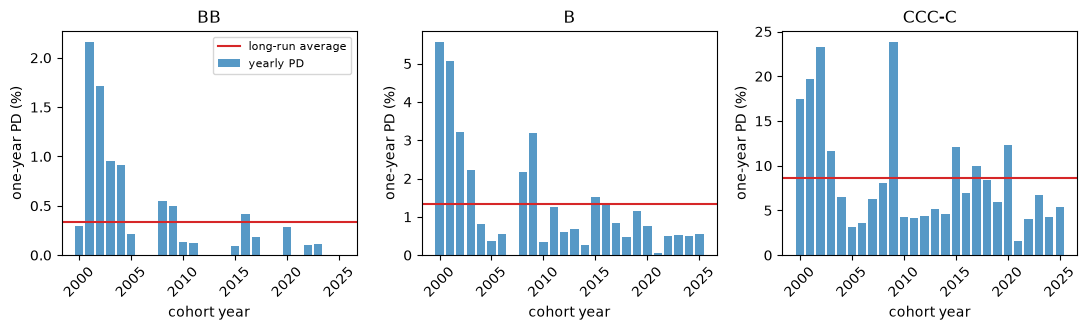

In [9]:
# Draw the yearly PD of BB, B and CCC-C as bars with the long-run average as a line
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, g in zip(axes, (4, 5, 6)):
    ax.bar(range(len(years)), 100 * yearly[:, g], color="tab:blue", alpha=0.75, label="yearly PD")
    ax.axhline(100 * lra[g], color="tab:red", label="long-run average")
    ax.set_xticks(range(0, len(years), 5))
    ax.set_xticklabels(years[::5], rotation=45)
    ax.set_title(grades[g])
    ax.set_xlabel("cohort year")
    ax.set_ylabel("one-year PD (%)")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

The yearly rate swings around its average (note the different vertical scales): B runs from zero to 5.57% around an average of 1.33%, and CCC-C from 1.58% to 23.86% around 8.61%. The table names the years behind the extremes, 2000 to 2002 and 2009 for the weak grades, the two recessions of the sample. The average is the number a master scale uses, and the yearly rate is what a point-in-time system reports. The figure does not say how much of the swing is the economy and how much is chance in a cohort of a few hundred ratings; the interval of the table gives that scale for the pooled rate.

### Step 4: the link between the two, the one-factor model

Why does the yearly rate swing around the average? The Merton-Vasicek model gives each obligor an asset return $A = \sqrt{\rho}\, Z + \sqrt{1-\rho}\, \varepsilon$, with a systematic factor $Z$ shared by all obligors (the economy) and an idiosyncratic one $\varepsilon$; the obligor defaults when $A$ falls below $\Phi^{-1}(p)$, where $p$ is the through-the-cycle PD. Given the state of the economy $Z = z$ the default probability, the point-in-time PD, is

$$p_{\mathrm{PIT}}(z) = \Phi\!\left(\frac{\Phi^{-1}(p) - \sqrt{\rho}\, z}{\sqrt{1-\rho}}\right)$$

(Vasicek, 2002). A low $z$ is a bad year. Inverting the formula, an observed yearly default rate $\mathrm{DR}_t$ implies the factor $z_t = \bigl(\Phi^{-1}(p) - \sqrt{1-\rho}\,\Phi^{-1}(\mathrm{DR}_t)\bigr)/\sqrt{\rho}$: the credit-cycle index of that year. The engine has both directions, `vasicek.conditional_pd` and `vasicek.implied_factor`. The asset correlation $\rho$ is an assumption: the next cell takes the Basel III corporate value that `irb.correlation` gives at the grade's TTC PD (the IRB formula's value, not an estimate from these data). Grade B is used because it has a default in most years; a year with a rate of exactly zero implies no finite factor and is left out.

In [10]:
# The credit-cycle factor each year implies for grade B, and the PD that factors from -2 to +2 imply
ttc_pd = float(lra[5])
rho = irb.correlation("corporate", ttc_pd)
rate = yearly[:, 5]
usable = rate > 0
z = vasicek.implied_factor(rate[usable], ttc_pd, rho)
used_years = [yr for yr, ok in zip(years, usable) if ok]
order = np.argsort(z)
grid = np.array([-2.0, -1.0, 0.0, 1.0, 2.0])
pit = vasicek.conditional_pd(ttc_pd, rho, grid)

print("TTC PD of B:", f"{100 * ttc_pd:.2f}%", "| rho:", round(rho, 4))
print("years with a default rate above zero:", len(z), "of", len(years))
print("lowest factors:", [(used_years[k], round(float(z[k]), 2)) for k in order[:3]])
print("highest factors:", [(used_years[k], round(float(z[k]), 2)) for k in order[::-1][:3]])
print("point-in-time PD at z = -2, -1, 0, 1, 2:",
      [f"{100 * v:.2f}%" for v in pit])

TTC PD of B: 1.33% | rho: 0.1817
years with a default rate above zero: 25 of 26
lowest factors: [('2000', -1.82), ('2001', -1.73), ('2002', -1.28)]
highest factors: [('2021', 1.62), ('2014', 0.7), ('2010', 0.54)]
point-in-time PD at z = -2, -1, 0, 1, 2: ['6.57%', '2.39%', '0.71%', '0.17%', '0.03%']


The next cell draws two panels: the factor each year implies for grade B, and the curve that turns any factor into a point-in-time PD.

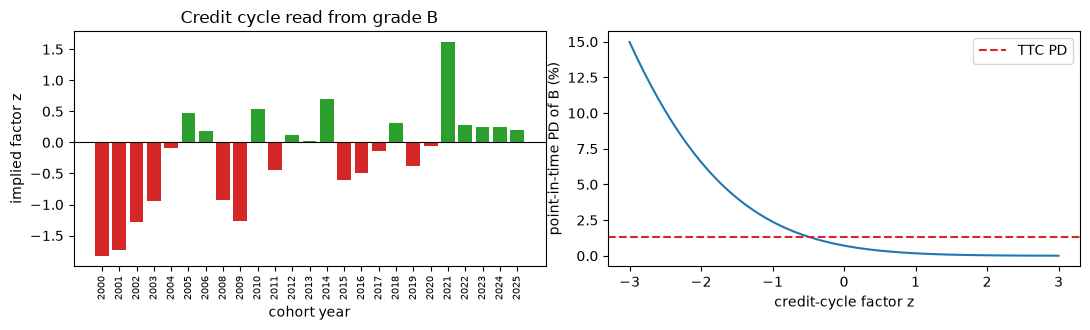

In [11]:
# Draw the factor each year implies (left) and the point-in-time PD it maps to (right)
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.4))
left.bar(range(len(z)), z, color=["tab:red" if v < 0 else "tab:green" for v in z])
left.axhline(0, color="black", linewidth=0.8)
left.set_xticks(range(len(z)))
left.set_xticklabels(used_years, rotation=90, fontsize=7)
left.set_xlabel("cohort year")
left.set_ylabel("implied factor z")
left.set_title("Credit cycle read from grade B")
zz = np.linspace(-3, 3, 61)
right.plot(zz, 100 * vasicek.conditional_pd(ttc_pd, rho, zz), color="tab:blue")
right.axhline(100 * ttc_pd, color="tab:red", linestyle="--", label="TTC PD")
right.set_xlabel("credit-cycle factor z")
right.set_ylabel("point-in-time PD of B (%)")
right.legend()
fig.tight_layout()
plt.show()

On the left, the bars below zero are the years worse than the average cycle: 2000, 2001, 2002 and 2009 are the lowest, as the recessions suggest. The mean of the usable factors is -0.21 and not the zero of a standard normal. Twenty-six years from 2000 are a small sample of a cycle, and the correlation is an assumption, so the factor is an index of the cycle and not a measurement of it. On the right, the model turns a factor into a PD: a two-standard-deviation bad year takes B's PD from its 1.33% average to 6.57%, and a good year of the same size brings it down to 0.03%. The PD answers bad years far more than it answers good ones.

### Step 5: the TTC portfolio of the pooled matrix

A matrix gives the TTC PD a second way. If the portfolio is propagated year after year with the pooled one-year matrix, its defaulted part written off and re-originated with the observed cohort mix, it converges to one portfolio, the through-the-cycle portfolio $W_{\mathrm{ttc}}$ of Engelmann (2024), whose default rate is $W_{\mathrm{ttc}}' T V_w$ (with $V_w$ the default column). The engine's `ttc_portfolio` iterates that map. It takes the pooled matrix of the previous step and the origination mix the artifact holds, and the next cell prints when it converges and what it carries. Notebook 07 develops the formula and its drift.

In [12]:
# Iterate the pooled matrix with the observed origination mix until the portfolio stops moving
origination = np.array(out["origination"], dtype=float)
result = ttc.ttc_portfolio(pooled["matrix"], origination)

print("iterations:", result["iterations"], "| converged:", result["converged"])
print("default rate of the TTC portfolio:", f"{100 * result['default_rate']:.2f}%")
latest = sp["impact"]["latest_default_rate"]["value"]
print("default rate of the latest cohort's mix, from the artifact:",
      f"{100 * latest:.2f}%")

iterations: 697 | converged: True
default rate of the TTC portfolio: 0.61%
default rate of the latest cohort's mix, from the artifact: 0.77%


The next cell sets the origination mix beside the portfolio the iteration converged to, state by state.

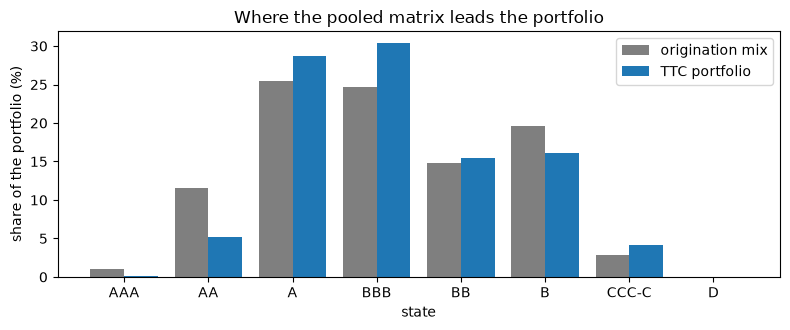

In [13]:
# Draw the origination mix and the through-the-cycle portfolio it converges to
fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(states))
ax.bar(x - 0.2, 100 * origination, 0.4, color="tab:gray", label="origination mix")
ax.bar(x + 0.2, 100 * result["portfolio"], 0.4, color="tab:blue", label="TTC portfolio")
ax.set_xticks(x)
ax.set_xticklabels(states)
ax.set_xlabel("state")
ax.set_ylabel("share of the portfolio (%)")
ax.set_title("Where the pooled matrix leads the portfolio")
ax.legend()
fig.tight_layout()
plt.show()

The through-the-cycle portfolio drifts away from the mix the bank originates: it holds more A, BBB and CCC-C and fewer AAA, AA and B, because the matrix moves ratings toward the middle of the scale and the written-off defaults are replaced by the fixed mix. Its default rate is 0.61%, against 0.77% for the latest cohort's mix, so the level of the portfolio's PD depends on which mix is used to weigh the grades, not only on the grade PDs. The bars do not show the speed of the convergence or its sensitivity to the withdrawals; notebook 07 takes up the drift.

## Results

**Answer:** a grade's master-scale PD is the average of its yearly rates: 0.005% for AA, 0.030% for A, 0.079% for BBB, 0.34% for BB, 1.33% for B and 8.61% for CCC-C, rising with the grade. A single year strays far from it: grade B was at 5.57% in 2000 and CCC-C at 17.43%, and the whole range of CCC-C runs from 1.58% to 23.86%. The yearly rate depends on the cycle, so a one-year PD is not a master-scale PD.

- **The withdrawn ratings move the PD.** Keeping them as an absorbing state lowers B's 2000 PD from 5.57% to 4.95% and CCC-C's from 17.43% to 13.38%, because 11.1% of the B ratings and 23.2% of the CCC-C ratings were withdrawn within the year. Whether a withdrawal says nothing about the borrower is an assumption.
- **The cycle is readable.** With the Basel III corporate correlation (an assumption, 0.18 at B's PD), the yearly default rate of grade B implies a credit-cycle factor whose lowest years are 2000, 2001 and 2002.
- **A second route to the same level.** Iterating the pooled matrix with the observed origination mix gives a through-the-cycle portfolio whose default rate is 0.61%, against 0.77% for the latest cohort's mix.

What this notebook does not show: how the cohort, duration and Aalen-Johansen estimators differ (notebook 02), whether a one-year matrix describes a cohort over several years (notebook 04), or how a PD becomes capital (notebook 07).

## Summary

- A rating agency's cohort table gives, per grade, where the ratings stood a year later; the share that ended in default, over the ratings still observed, is the one-year PD of the grade.
- Withdrawn ratings are removed by the industry treatment and kept by the EBA paragraph 76 reading; the two differ most in the weakest grades.
- A master scale needs the through-the-cycle PD, the average of many yearly rates; the one-factor model links the two and reads a credit-cycle factor from each year.
- A pooled matrix, iterated with the origination mix, leads to a portfolio whose default rate is a second reading of the through-the-cycle level.

**What to try next.** Change the grade in Step 4 from B to BB and compare the worst years; then read notebook 02 and continue with the duration estimator.

## References

- ESMA, CEREP publication of credit rating agency ratings and transitions, with the help file ESMA65-8-10634. https://registers.esma.europa.eu/cerep-publication/
- Anderson, T. W. and Goodman, L. A. (1957), Statistical inference about Markov chains, Annals of Mathematical Statistics 28(1), equations 2.8 and 2.9. https://doi.org/10.1214/aoms/1177707039
- Schuermann, T. and Hanson, S. (2004), Estimating probabilities of default, FRBNY Staff Report 190, footnote 4. https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr190.pdf
- EBA (2017), Guidelines on PD estimation, LGD estimation and the treatment of defaulted exposures, EBA/GL/2017/16, paragraphs 76, 84 and 86.
- Vasicek, O. (2002), Loan portfolio value, Risk, December 2002, 160-162.
- Engelmann, B. (2024), Spurious default probability projections in credit risk stress testing models, arXiv 2401.08892.